# RetailOps, notebook 1: the ML demand forecaster

**Course:** CS2105 Optimization Techniques, IIT Patna. **Project:** RetailOps, stock ordering for a
10-store food chain on real Walmart sales (the Kaggle M5 data).

Before a store can decide **how much to order**, it needs a guess of **how much it will sell**.
This notebook explains and reproduces that guess: the machine-learning (ML) forecaster.

What it does, top to bottom:

1. loads the settings, the sales history and the product list (the `forecast.data` module);
2. shows a few facts about the data, with a chart of the time windows;
3. explains what a *quantile forecast* is and how it is scored (pinball loss, coverage);
4. explains the **2-day rule** that stops the model from peeking at the future, and proves it on real rows;
5. shows the validation scores against two simple baselines (read from the saved score files);
6. loads the **frozen** model and writes the forecasts for the 56 test days to
   `outputs/notebooks/forecasts.parquet`, then checks they are identical to the project's file
   `data/processed/forecasts.parquet`;
7. draws one product's forecast fan over the test window;
8. (optional, off by default) retrains the model from scratch with `RETRAIN = True`.

**Ground rules this notebook keeps:** it only *calls* the project code (`forecast/`), it never changes
it; it never reads the sealed holdout data; it never overwrites the frozen model or the frozen
forecasts file. Everything it writes goes to `outputs/notebooks/`.

Runtime with the default flags: about 1 to 2 minutes on the laptop.

In [1]:
# Setup: work from the project root (the folder that holds config.yaml), whatever folder Jupyter started in.
import os
import sys
import json
import time
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
assert (ROOT / "config.yaml").exists() and (ROOT / "forecast").is_dir(), f"not the project root: {ROOT}"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

OUT = Path("outputs/notebooks")          # everything this notebook writes goes here
OUT.mkdir(parents=True, exist_ok=True)
print("project root:", ROOT.name, "| outputs go to", OUT)

project root: RetailOps | outputs go to outputs\notebooks


## 1. Settings, sales and products

Every assumed number lives in `config.yaml`; the code has no hidden constants.
`forecast.data.load_config` reads it, `load_sales` reads `data/processed/sales.parquet` and **refuses**
the file if it holds even one row from the sealed holdout (rule R1), and `load_items` reads the product
list (which items are perishable, their shelf life and their average daily sales).

**Time windows.** The data is split by date, never shuffled, because in real life you always forecast the
future from the past:

| window | what it is used for |
|---|---|
| warm-up | history only, so the first training days have past data to look back on |
| train | fitting the model |
| validation | choosing settings and checking honesty (two folds, see section 5) |
| test | the 8-week replay of the ordering methods (Thanksgiving + Christmas 2015) |
| holdout | **sealed**: run once after the code freeze, in blocks (blocks 1 and 2 done, block 3 still sealed); not used here |

In [2]:
from forecast.data import load_config, load_sales, load_items, windows, val_folds

cfg = load_config("config.yaml")
W = windows(cfg)
FOLDS = val_folds(cfg)
sales = load_sales(cfg)          # raises if any row is on or after holdout_start
items = load_items(cfg)

f = cfg["forecast"]
print(f"sales rows: {len(sales):,}  |  {sales.store_id.nunique()} stores x {sales.item_id.nunique()} items"
      f"  |  {sales.date.min().date()} to {sales.date.max().date()}")
print(f"perishable items: {int(items.is_perishable.sum())} of {len(items)}  |  "
      f"slow sellers (< {f['slow_seller_max_avg_units']} units/day): {int((items.avg_daily_units < f['slow_seller_max_avg_units']).sum())}")
print(f"quantiles {f['quantiles']}  |  horizon {f['horizon_days']} days  |  "
      f"min_lag_days {f['min_lag_days']}  |  lags {f['lags']}  |  rolling windows {f['rolling_windows']}")

win_table = pd.DataFrame([
    ("warm-up", W["warmup_start"], W["train_start"] - pd.Timedelta(days=1)),
    ("train", W["train_start"], W["train_end"]),
    ("validation", W["val_start"], W["val_end"]),
    ("test (replay)", W["test_start"], W["test_end"]),
    ("holdout (sealed)", W["holdout_start"], W["holdout_end"]),
], columns=["window", "start", "end"])
win_table["days"] = (win_table.end - win_table.start).dt.days + 1
win_table["start"], win_table["end"] = win_table.start.dt.date, win_table.end.dt.date
win_table

sales rows: 1,334,756  |  10 stores x 120 items  |  2012-11-26 to 2015-12-26
perishable items: 20 of 120  |  slow sellers (< 5.0 units/day): 24
quantiles [0.5, 0.8, 0.9, 0.95]  |  horizon 2 days  |  min_lag_days 2  |  lags [2, 7, 14, 21, 28]  |  rolling windows [7, 28]


,window,start,end,days
0,warm-up,2012-11-26,2012-12-31,36
1,train,2013-01-01,2015-06-30,911
2,validation,2015-07-01,2015-10-31,123
3,test (replay),2015-11-01,2015-12-26,56
4,holdout (sealed),2015-12-27,2016-05-22,148


### Data facts

The chart adds up all 1,200 store-items per day. Shaded areas are the windows above; the two hatched
stretches are the **validation folds** (section 5). The chain-wide total dips to almost nothing every
25 December (stores closed: 7 to 15 units chain-wide), which is why the forecaster sets every line to
0 on that day and leaves it out of every score.

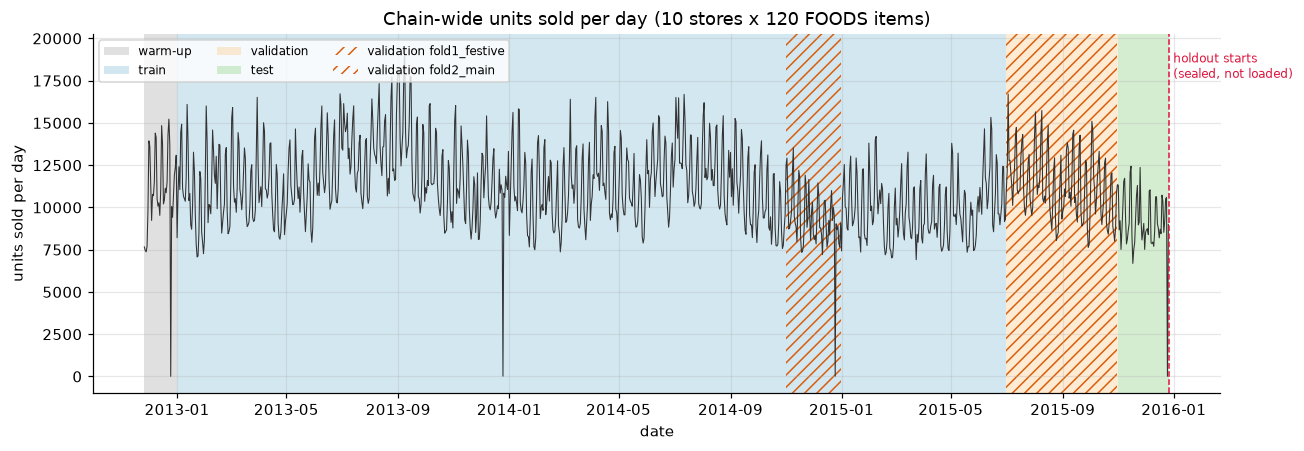

three biggest days: 2013-09-08 (19,286), 2013-09-01 (18,076), 2013-09-02 (18,041)
three smallest days: 2012-12-25 (7), 2015-12-25 (10), 2014-12-25 (15)


In [3]:
daily = sales.groupby("date")["units"].sum()

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(daily.index, daily.values, lw=0.7, color="#333333")
shade = [("warm-up", W["warmup_start"], W["train_start"], "#bbbbbb"),
         ("train", W["train_start"], W["val_start"], "#9ecae1"),
         ("validation", W["val_start"], W["test_start"], "#fdd49e"),
         ("test", W["test_start"], W["test_end"] + pd.Timedelta(days=1), "#a1d99b")]
for name, a, b, c in shade:
    ax.axvspan(a, b, color=c, alpha=0.45, lw=0, label=name)
for fo in FOLDS:
    ax.axvspan(fo["val_start"], fo["val_end"], fill=False, hatch="///", edgecolor="#d95f0e", lw=0,
               label=f"validation {fo['name']}")
ax.axvline(W["holdout_start"], color="crimson", ls="--", lw=1)
ax.text(W["holdout_start"], ax.get_ylim()[1] * 0.95, " holdout starts\n (sealed, not loaded)",
        color="crimson", va="top", fontsize=8)
ax.set_title("Chain-wide units sold per day (10 stores x 120 FOODS items)")
ax.set_xlabel("date")
ax.set_ylabel("units sold per day")
ax.legend(loc="upper left", fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

top = daily.sort_values(ascending=False).head(3)
low = daily.sort_values().head(3)
print("three biggest days:", ", ".join(f"{d.date()} ({v:,.0f})" for d, v in top.items()))
print("three smallest days:", ", ".join(f"{d.date()} ({v:,.0f})" for d, v in low.items()))

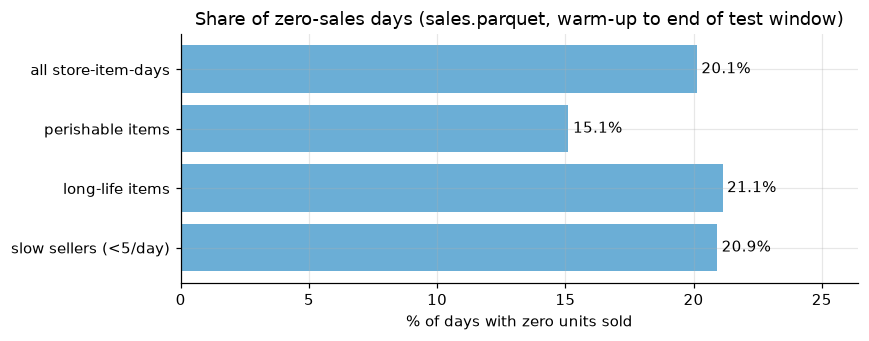

In [4]:
# How often does a store-item sell nothing on a day? (many 0 days make forecasting harder)
seg = sales.merge(items[["item_id", "avg_daily_units"]], on="item_id")
slow_cut = cfg["forecast"]["slow_seller_max_avg_units"]
groups = {
    "all store-item-days": seg,
    "perishable items": seg[seg.is_perishable],
    "long-life items": seg[~seg.is_perishable],
    f"slow sellers (<{slow_cut:g}/day)": seg[seg.avg_daily_units < slow_cut],
}
zero_share = pd.Series({k: (g.units == 0).mean() * 100 for k, g in groups.items()})

fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.barh(zero_share.index[::-1], zero_share.values[::-1], color="#6baed6")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("% of days with zero units sold")
ax.set_title("Share of zero-sales days (sales.parquet, warm-up to end of test window)")
ax.set_xlim(0, max(zero_share.max() * 1.25, 10))
plt.tight_layout()
plt.show()

## 2. What the model predicts: quantile lines

A single number such as "we will sell 10 tomorrow" hides the risk. The forecaster instead gives **four
lines** for every store, item and day:

- **q50** (the median): half of the days, sales are at or below it;
- **q80, q90, q95**: 80%, 90%, 95% of days, sales should be at or below it.

*Example:* if q50 = 10 and q95 = 18 for milk at store CA_1 tomorrow, a manager who stocks 18 should run
out on only about 1 day in 20. The order model (notebook 2) chooses which line to stock to, item by item.

**How a quantile line is trained: the pinball loss.** For the 90% line, a forecast that is too **low**
costs 0.9 per unit missed, and a forecast that is too **high** costs only 0.1 per unit over. Missing low
is 9 times worse, so the model pushes the line up until about 90% of days fall under it.

*Worked example* (q = 0.9, forecast 10):
- sales turn out 14: under by 4, loss = 0.9 x 4 = **3.6**;
- sales turn out 6: over by 4, loss = 0.1 x 4 = **0.4**.

**Coverage** checks the result: the share of days on which sales were at or below the line. A good q90
line has coverage near 90%. **MAE** (mean absolute error) is the average number of units the q50 line is
off by per day; it equals 2 x the q50 pinball loss.

The cell below checks these numbers with the project's own scoring functions (`forecast.metrics`).

In [5]:
from forecast.metrics import pinball, coverage, mae

print("pinball, q=0.9, forecast 10, sales 14:", pinball([14], [10], 0.9))
print("pinball, q=0.9, forecast 10, sales  6:", round(pinball([6], [10], 0.9), 4))

y = np.array([3, 8, 10, 12, 15, 6, 9, 30, 11, 7])     # ten days of sales
line = np.full(10, 14.0)                               # a flat line at 14
print(f"coverage of a line at 14 over these 10 days: {coverage(y, line):.0f}%  (9 of 10 days at or below 14)")
print(f"MAE of a q50 of 10: {mae(y, np.full(10, 10.0)):.1f} units/day = 2 x pinball {pinball(y, np.full(10, 10.0), 0.5):.2f}")

pinball, q=0.9, forecast 10, sales 14: 3.6
pinball, q=0.9, forecast 10, sales  6: 0.4
coverage of a line at 14 over these 10 days: 80%  (9 of 10 days at or below 14)
MAE of a q50 of 10: 4.5 units/day = 2 x pinball 2.25


## 3. The 2-day rule (R2) and why it prevents leakage

**Leakage** means the model uses information that would not exist yet at the moment the decision is made.
A leaky model looks brilliant in testing and fails in real use. For example, if "tomorrow's sales" used
"today's sales" as an input, the forecast made this morning would need numbers that only exist tonight.

Each morning (the **origin**) the store orders for **today and tomorrow** (`horizon_days = 2`). The rule:

> every input taken from the store's own records (sales, prices, averages, spreads, ranks) must be
> **at least 2 days older than the day being forecast** (`min_lag_days = 2`).

- For **tomorrow**, 2 days back is **yesterday**, the newest day that is fully known this morning.
- For **today**, 2 days back is the day before yesterday. Yesterday is known, but one model serves both
  days, so both use the same "2 days or older" inputs. Because `horizon_days <= min_lag_days`,
  no forecast ever needs a day that has not happened (`load_config` refuses any other setting).

**Calendar inputs are the exception (R3):** day of week, month, holiday names, SNAP food-stamp days and
"days until the next event" are published in advance, so they may be for the target day itself.
They come from `data/m5/calendar.csv`, never from sales.

The table below is the project's own list (`forecast.features.feature_sources`) of the fewest days back
each store-data input reads. The code refuses any input that is not on this list.

In [6]:
from forecast.features import (feature_names, feature_sources, fit_encoders, build_features,
                               CALENDAR_FEATURES, ID_FEATURES)

src = pd.Series(feature_sources(cfg), name="fewest days back it reads").to_frame()
src["meaning"] = src.index.map(lambda n:
    "units sold n days before the target" if n.startswith("lag_") else
    "average units over a window ending 2 days back" if n.startswith("roll_mean") else
    "spread (std) of units over 28 days ending 2 days back" if n.startswith("roll_std") else
    "price 2 days back" if n.startswith("price_2") else
    "price change vs the 4 weeks before" if n.startswith("price_chg") else
    "price vs the item's normal price" if n == "price_rel_item" else
    "7-day average / 28-day average (trend)" if n == "momentum" else
    "rank of the item's sales inside its store (0-1)")
print("store-data inputs (rule R2):")
display(src)
print("calendar inputs (allowed same-day, R3):", CALENDAR_FEATURES)
print("who inputs (store, item, department, perishable flag):", ID_FEATURES)
print(f"total model inputs: {len(feature_names(cfg))}")

store-data inputs (rule R2):


,fewest days back it reads,meaning
lag_2,2,units sold n days before the target
lag_7,7,units sold n days before the target
lag_14,14,units sold n days before the target
lag_21,21,units sold n days before the target
lag_28,28,units sold n days before the target
roll_mean_7,2,average units over a window ending 2 days back
roll_mean_28,2,average units over a window ending 2 days back
roll_std_28,2,spread (std) of units over 28 days ending 2 da...
price_2,2,price 2 days back
price_chg_4w,2,price change vs the 4 weeks before


calendar inputs (allowed same-day, R3): ['wday', 'month', 'is_event', 'event_name', 'snap', 'days_to_event', 'days_since_event', 'next_event_name']
who inputs (store, item, department, perishable flag): ['store_id', 'item_id', 'dept_id', 'is_perishable']
total model inputs: 25


### The inputs for a few real rows, and a proof that the future cannot leak in

We build the inputs for three store-items, for today and tomorrow, as on the morning of the first test day
(1 Nov 2015). Category codes and each item's normal price are fitted only on rows before that morning (R4).

Then two **poison tests** (the project's test suite runs the same idea in `tests/test_forecast_fairness.py`):

1. replace every sale and price **on or after the origin** with nonsense: **no input may change**;
2. replace **yesterday's** sales: today's inputs must not change, tomorrow's may (yesterday is known
   this morning, and tomorrow's `lag_2` is yesterday).

In [7]:
origin = W["test_start"]
rank = items.sort_values("rank")
demo_items = [rank[rank.is_perishable].item_id.iloc[0],                               # top perishable
              rank[~rank.is_perishable].item_id.iloc[0],                              # top long-life
              rank[rank.avg_daily_units < cfg["forecast"]["slow_seller_max_avg_units"]].item_id.iloc[0]]  # a slow seller
demo_pairs = pd.DataFrame({"store_id": ["CA_1", "TX_2", "WI_3"], "item_id": demo_items})
targets = (pd.DataFrame({"date": pd.date_range(origin, periods=cfg["forecast"]["horizon_days"])})
           .merge(demo_pairs, how="cross"))

known = sales[sales.date < origin]                     # everything known on the origin's morning
enc = fit_encoders(known, cutoff=origin)
X = build_features(known, targets, cfg, enc)
X.index = [f"{r.store_id} {r.item_id} {r.date.date()}" for r in targets.itertuples()]
print(f"origin (the ordering morning): {origin.date()}  |  items: {demo_items}")
X.T.round(3)

origin (the ordering morning): 2015-11-01  |  items: ['FOODS_3_090', 'FOODS_3_080', 'FOODS_3_042']


,CA_1 FOODS_3_090 2015-11-01,TX_2 FOODS_3_080 2015-11-01,WI_3 FOODS_3_042 2015-11-01,CA_1 FOODS_3_090 2015-11-02,TX_2 FOODS_3_080 2015-11-02,WI_3 FOODS_3_042 2015-11-02
lag_2,77.000000,25.000000,7.000,101.000000,11.000,8.000
lag_7,72.000000,4.000000,6.000,40.000000,20.000,16.000
lag_14,101.000000,19.000000,8.000,39.000000,14.000,6.000
lag_21,107.000000,27.000000,3.000,76.000000,20.000,6.000
lag_28,65.000000,22.000000,9.000,37.000000,11.000,9.000
roll_mean_7,64.429001,17.000000,9.000,61.570999,15.571,8.571
roll_mean_28,60.000000,17.964001,8.250,60.035999,17.607,8.036
roll_std_28,26.455000,5.330000,2.989,26.511000,5.452,2.769
price_2,1.500000,1.680000,1.680,1.500000,1.680,1.680
price_chg_4w,0.007000,0.000000,0.000,0.007000,0.000,0.000


In [8]:
def same(a, b):
    # equal, counting NaN == NaN
    return bool(np.array_equal(a.to_numpy(), b.to_numpy(), equal_nan=True))

window = sales[sales.date <= origin + pd.Timedelta(days=6)]          # includes days after the origin
base = build_features(window, targets, cfg, enc)

poison = window.copy()
late = poison.date >= origin
poison.loc[late, "units"] = 9999
poison.loc[late, "price"] = 0.01
test1 = same(base, build_features(poison, targets, cfg, enc))
print(f"poison test 1: sales/prices on or after {origin.date()} replaced -> inputs unchanged: {test1}")

poison2 = window.copy()
poison2.loc[poison2.date == origin - pd.Timedelta(days=1), "units"] = 9999
X2 = build_features(poison2, targets, cfg, enc)
today_rows = (targets.date == origin).to_numpy()
print(f"poison test 2: yesterday replaced -> today's inputs unchanged: {same(base[today_rows], X2[today_rows])}; "
      f"tomorrow's inputs changed: {not same(base[~today_rows], X2[~today_rows])}")
changed = [c for c in base.columns if not np.array_equal(base.loc[~today_rows, c], X2.loc[~today_rows, c], equal_nan=True)]
print("   tomorrow's inputs that read yesterday:", changed)
assert test1

poison test 1: sales/prices on or after 2015-11-01 replaced -> inputs unchanged: True


poison test 2: yesterday replaced -> today's inputs unchanged: True; tomorrow's inputs changed: True
   tomorrow's inputs that read yesterday: ['lag_2', 'roll_mean_7', 'roll_mean_28', 'roll_std_28', 'momentum', 'store_rank_28']


## 4. The model

- **Gradient-boosted trees** (`sklearn.ensemble.HistGradientBoostingRegressor`). A *decision tree*
  splits the rows with yes/no questions ("is lag_7 above 12?", "is it a Saturday?") and predicts a number
  for each group. *Boosting* adds hundreds of small trees one after another, each fixing the errors of
  the trees before it.
- **One global model per line**, trained with `loss="quantile"` at 0.5, 0.8, 0.9 and 0.95. "Global" means
  one model learns from all 1,200 store-items at once, so a slow item borrows patterns from similar items.
- **Settings per line** (learning rate, number of trees, tree size) were chosen on the validation folds
  only (rule R6); they are below.
- **Dead-item rule** (decision 26): if a store-item sold nothing in the 28 days ending 2 days back, q50 is
  set to 0 (upper lines keep the model's value, so an item that comes back still gets some stock).
- **Post-processing:** the four lines are sorted so they never cross (q50 <= q80 <= q90 <= q95), clipped at
  0, and set to 0 on 25 December (stores closed).
- **Calibration k:** if a line's validation coverage were off by more than 3 points, it would be stretched
  as `q50 + k x (line - q50)` with one k per line (k > 1 widens the gap to q50, k < 1 narrows it). On the
  validation folds every upper line was already within 3 points, so **all k = 1** (nothing stretched).
- **Frozen:** the final model was trained once on 2013-01-01 to 2015-10-31 (cutoff 2015-11-01) and saved
  with a `manifest.json`. Loading refuses the model if the config changed, the scikit-learn version
  differs, or the cutoff is after the replay start.

In [9]:
from forecast.model import model_params

params = pd.DataFrame({name: p for name, p in zip(["q50", "q80", "q90", "q95"], model_params(cfg).values())}).T
display(params)

manifest = json.loads((Path(cfg["forecast"]["model_dir"]) / "manifest.json").read_text(encoding="utf-8"))
print({k: manifest[k] for k in ["cutoff", "train_rows", "seed", "sklearn_version", "shifts", "platform"]})

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
q50,0.10,300.0,31.0,50.0
q80,0.05,150.0,63.0,50.0
q90,0.05,600.0,31.0,50.0
q95,0.05,450.0,63.0,50.0


{'cutoff': '2015-11-01', 'train_rows': 1226019, 'seed': 1, 'sklearn_version': '1.9.1', 'shifts': {'q50': 0.0, 'q80': 1.0, 'q90': 1.0, 'q95': 1.0}, 'platform': 'Windows 11 / Python 3.14.7'}


## 5. Validation: does the model beat simple rules?

**Two validation folds**, each with its own model trained only on days before the fold:

- `fold1_festive`: 1 Nov to 31 Dec 2014 (Thanksgiving + Christmas), model trained up to 31 Oct 2014;
- `fold2_main`: 1 Jul to 31 Oct 2015 (ordinary months), model trained up to 30 Jun 2015.

A setting was kept only if it helped on **both** folds, so the model is not tuned to one lucky period.

**Two baselines** the model must beat:

- **naive**: q50 = sales on the same weekday last week;
- **stub**: q50 = average of the sales 7, 14, 21 and 28 days back (the placeholder forecast the order
  model was first built on).

Both baselines make their upper lines as q50 + z x (28-day spread), with z from the normal curve.

The numbers below are read from the saved score files in `outputs/forecast/scores/` with the project's
own reader `forecast.report.collect` (the same one that made the slide report). Nothing is retrained.
25 December is left out of every score.

In [10]:
from forecast.report import collect
%matplotlib inline
# (forecast.report switches matplotlib to its file-only backend when imported; the line above switches back)

scores_dir = Path(cfg["forecast"]["scores_dir"])
data = collect(scores_dir)
scores, cal = data["scores"], data["calibration"]

rows = []
for fold, by_method in scores.items():
    for method, r in by_method.items():
        rows.append({"fold": fold, "method": method, "MAE": r["mae"],
                     **{f"pinball {q}": r[f"pinball_{q}"] for q in ["q50", "q80", "q90", "q95"]},
                     **{f"cover {q} %": r[f"cover_{q}"] for q in ["q50", "q80", "q90", "q95"]}})
score_table = pd.DataFrame(rows)
display(score_table.round(3))

for fold in scores:
    m, s = scores[fold]["model"]["mae"], scores[fold]["stub (4-week average)"]["mae"]
    print(f"{fold}: model MAE {m:.3f} vs stub {s:.3f} -> {100 * (s - m) / s:.1f}% lower")

,fold,method,MAE,pinball q50,pinball q80,pinball q90,pinball q95,cover q50 %,cover q80 %,cover q90 %,cover q95 %
0,fold1_festive,naive baseline,4.883,2.442,1.971,1.398,0.964,62.001,77.815,84.643,88.935
1,fold1_festive,stub (4-week average),4.389,2.195,1.805,1.284,0.883,60.904,80.514,86.989,90.628
2,fold1_festive,model,3.550,1.775,1.554,1.102,0.727,56.667,82.009,90.373,94.458
3,fold2_main,naive baseline,5.210,2.605,2.077,1.464,1.003,59.653,77.767,85.187,89.570
4,fold2_main,stub (4-week average),4.725,2.362,1.939,1.374,0.943,59.236,80.365,87.258,91.082
5,fold2_main,model,3.817,1.908,1.572,1.094,0.712,54.152,80.946,90.203,94.749


fold1_festive: model MAE 3.550 vs stub 4.389 -> 19.1% lower
fold2_main: model MAE 3.817 vs stub 4.725 -> 19.2% lower


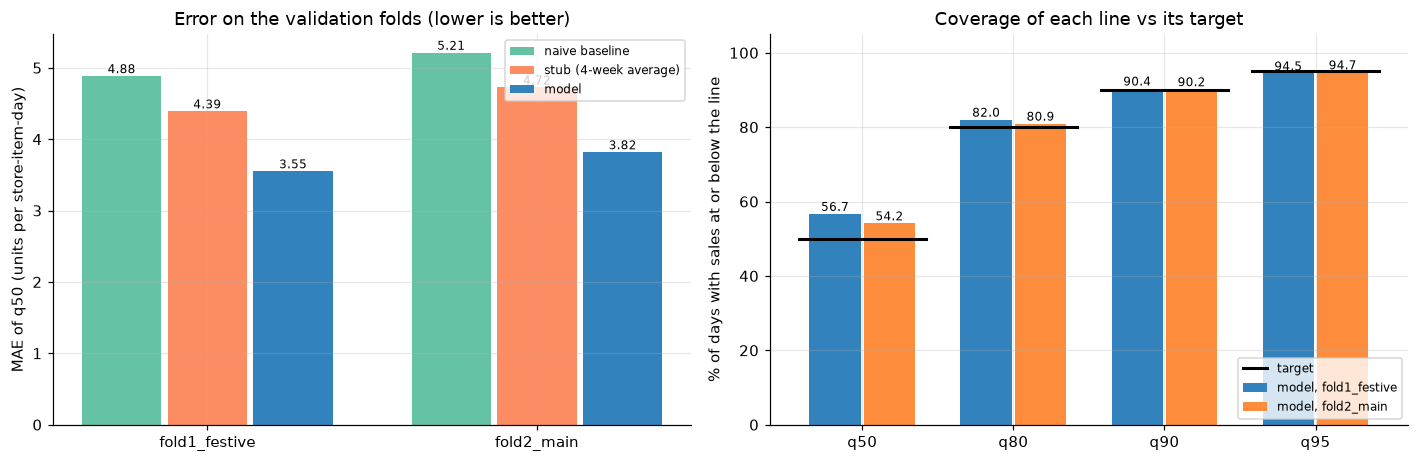

In [11]:
folds = list(scores)
methods = ["naive baseline", "stub (4-week average)", "model"]
colors = ["#66c2a5", "#fc8d62", "#3182bd"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
w = 0.26
for i, (name, c) in enumerate(zip(methods, colors)):
    xs = np.arange(len(folds)) + (i - 1) * w
    vals = [scores[fo][name]["mae"] for fo in folds]
    b = ax.bar(xs, vals, width=w - 0.02, color=c, label=name)
    ax.bar_label(b, fmt="%.2f", fontsize=8)
ax.set_xticks(range(len(folds)), folds)
ax.set_ylabel("MAE of q50 (units per store-item-day)")
ax.set_title("Error on the validation folds (lower is better)")
ax.legend(fontsize=8)

ax = axes[1]
lines = ["q50", "q80", "q90", "q95"]
w = 0.36
for i, (fo, c) in enumerate(zip(folds, ["#3182bd", "#fd8d3c"])):
    xs = np.arange(len(lines)) + (i - 0.5) * w
    vals = [scores[fo]["model"][f"cover_{q}"] for q in lines]
    b = ax.bar(xs, vals, width=w - 0.02, color=c, label=f"model, {fo}")
    ax.bar_label(b, fmt="%.1f", fontsize=8)
for j, q in enumerate(lines):
    t = float(q[1:])
    ax.plot([j - 0.42, j + 0.42], [t, t], color="black", lw=2)
ax.plot([], [], color="black", lw=2, label="target")
ax.set_xticks(range(len(lines)), lines)
ax.set_ylim(0, 105)
ax.set_ylabel("% of days with sales at or below the line")
ax.set_title("Coverage of each line vs its target")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**Reading the charts.** The model's daily error is about 19% below the stub on both folds, and every
upper line has a lower pinball loss than both baselines on both folds (table below). Coverage of
q80/q90/q95 sits within about 2 points of the target. q50 covers 54 to 57% instead of 50%: on a day with
0 sales and a q50 of 0, the day counts as "covered", and there are many such ties (counting a tie as half
gives about 51%). That is why the calibration gate below reports q50 as outside tolerance; the project
accepted this at gate D and changed nothing (`gate_passed` stays `False` for that reason only).

In [12]:
vs = pd.DataFrame(json.loads((scores_dir / "lines_vs_baselines.json").read_text(encoding="utf-8")))
display(vs.round(4))

print("calibration numbers (k per upper line, unit shift for q50):", cal["shifts"])
gate = pd.DataFrame({(fo, q): v for fo, by in cal["gate"].items() for q, v in by.items()}).T
display(gate)

,fold,line,model,naive,stub,beats_naive,beats_stub
0,fold1_festive,q80,1.5545,1.9705,1.8053,True,True
1,fold1_festive,q90,1.1023,1.3976,1.2836,True,True
2,fold1_festive,q95,0.7269,0.9636,0.8827,True,True
3,fold2_main,q80,1.5720,2.0768,1.9385,True,True
4,fold2_main,q90,1.0944,1.4642,1.3736,True,True
5,fold2_main,q95,0.7116,1.0028,0.9432,True,True


calibration numbers (k per upper line, unit shift for q50): {'q50': 0.0, 'q80': 1.0, 'q90': 1.0, 'q95': 1.0}


coverage target within
fold1_festive q50  56.666667   50.0  False
              q80  82.009476   80.0   True
              q90  90.373467   90.0   True
              q95  94.457915   95.0   True
fold2_main    q50  54.151762   50.0  False
              q80  80.945799   80.0   True
              q90  90.202575   90.0   True
              q95  94.748645   95.0   True

## 6. Write the forecasts with the frozen model, and check they match the project's file

`forecast.write_forecasts.write_forecasts` calls `forecast.predict.predict` once per origin (each of the
56 test days, 1 Nov to 26 Dec 2015). Each call:

- reads only sales dated **before** that origin (R1, R8);
- predicts today and tomorrow for all 1,200 store-items (56 x 2 x 1,200 = 134,400 rows);
- applies the dead-item rule, the calibration numbers (all 1 here) and the post-processing;
- gives a store-item with no sales history at all the stub baseline (0 on every line).

The output has exactly the columns of the agreed contract (`origin, date, store_id, item_id, q50, q80,
q90, q95`), so the order model can read it without changes. We write it to
`outputs/notebooks/forecasts.parquet`, then compare it with the frozen `data/processed/forecasts.parquet`
row by row and value by value.

In [13]:
from forecast.freeze import load_frozen
from forecast.write_forecasts import write_forecasts
from forecast.predict import CONTRACT

origins = pd.date_range(W["test_start"], W["test_end"], freq="D")
bundle = load_frozen(cfg["forecast"]["model_dir"], origins[0], cfg)   # the frozen model, after its 3 guards
print(f"frozen model loaded: cutoff {bundle.cutoff.date()}, lines {sorted(bundle.models)}, "
      f"{bundle.train_rows:,} training rows")

NB_FORECASTS = OUT / "forecasts.parquet"
t0 = time.time()
fc = write_forecasts(sales, origins, cfg, NB_FORECASTS, bundle=bundle)
print(f"{len(origins)} origins, {len(fc):,} rows, {fc.attrs['fallback_pairs']} fallback store-item-origins; "
      f"wrote {NB_FORECASTS} in {time.time() - t0:.0f} s")

frozen model loaded: cutoff 2015-11-01, lines [0.5, 0.8, 0.9, 0.95], 1,226,019 training rows


56 origins, 134,400 rows, 0 fallback store-item-origins; wrote outputs\notebooks\forecasts.parquet in 31 s


In [14]:
KEY = ["origin", "date", "store_id", "item_id"]
mine = pd.read_parquet(NB_FORECASTS).sort_values(KEY).reset_index(drop=True)
frozen = pd.read_parquet("data/processed/forecasts.parquet").sort_values(KEY).reset_index(drop=True)

assert list(mine.columns) == CONTRACT, mine.columns
pd.testing.assert_frame_equal(mine, frozen, check_exact=True)      # raises if any value differs
lines4 = ["q50", "q80", "q90", "q95"]
print(f"IDENTICAL: {len(mine):,} rows, columns {list(mine.columns)}")
print(f"max |difference| over the four lines: {np.abs(mine[lines4].to_numpy() - frozen[lines4].to_numpy()).max()}")
print("dtypes:", dict(mine.dtypes.astype(str)))

IDENTICAL: 134,400 rows, columns ['origin', 'date', 'store_id', 'item_id', 'q50', 'q80', 'q90', 'q95']
max |difference| over the four lines: 0.0
dtypes: {'origin': 'datetime64[ns]', 'date': 'datetime64[ns]', 'store_id': 'str', 'item_id': 'str', 'q50': 'float64', 'q80': 'float64', 'q90': 'float64', 'q95': 'float64'}


## 7. One product's forecast fan over the test window

The chart shows CA_1's best-selling perishable item: its sales in the 4 weeks before the test window,
then the same-day lines (forecast date = origin) for each of the 56 test mornings.

**Note on actual sales (rule R10):** the orange dots in the test window are the real sales. Showing them is
fine *now*, because the replay of the ordering methods on the test window is already finished; the
forecaster was never tuned on them. The forecasts themselves use only sales before each origin.

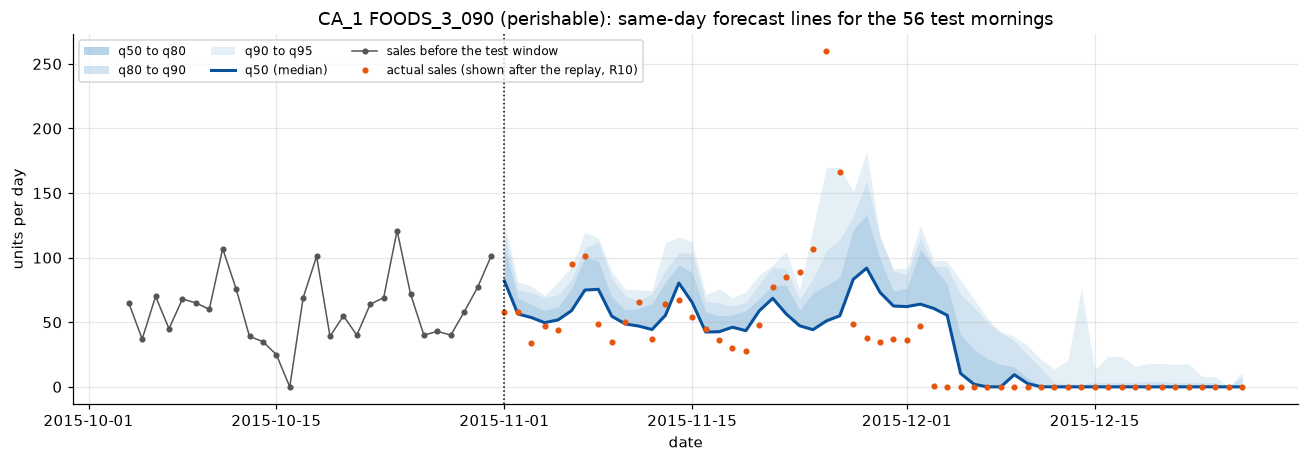

In [15]:
store, item = "CA_1", demo_items[0]
one = mine[(mine.store_id == store) & (mine.item_id == item) & (mine.date == mine.origin)].sort_values("date")
hist = sales[(sales.store_id == store) & (sales.item_id == item)]
before = hist[(hist.date >= W["test_start"] - pd.Timedelta(days=28)) & (hist.date < W["test_start"])]
after = hist[(hist.date >= W["test_start"]) & (hist.date <= W["test_end"])]

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.fill_between(one.date, one.q50, one.q80, color="#3182bd", alpha=0.35, lw=0, label="q50 to q80")
ax.fill_between(one.date, one.q80, one.q90, color="#3182bd", alpha=0.22, lw=0, label="q80 to q90")
ax.fill_between(one.date, one.q90, one.q95, color="#3182bd", alpha=0.12, lw=0, label="q90 to q95")
ax.plot(one.date, one.q50, color="#08519c", lw=2, label="q50 (median)")
ax.plot(before.date, before.units, color="#555555", marker=".", lw=1, label="sales before the test window")
ax.plot(after.date, after.units, color="#e6550d", marker="o", ms=3, lw=0, label="actual sales (shown after the replay, R10)")
ax.axvline(W["test_start"], color="black", ls=":", lw=1)
ax.set_title(f"{store} {item} (perishable): same-day forecast lines for the 56 test mornings")
ax.set_xlabel("date")
ax.set_ylabel("units per day")
ax.legend(fontsize=8, ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

Because the replay is done, we may also score the test window (R10 asks us to report it, good or bad).
This uses `forecast.metrics.score` on the same-day and next-day lines together, with 25 December left out.

In [16]:
from forecast.metrics import score, segments

actual = sales[(sales.date >= W["test_start"]) & (sales.date <= W["test_end"])]
seg_t = segments(sales, items, cfg)
test_rows = []
for name, part in [("same day (date = origin)", mine[mine.date == mine.origin]),
                   ("next day (date = origin + 1)", mine[mine.date > mine.origin])]:
    s = score(part.drop(columns="origin"), actual, seg_t, cfg)
    s.insert(0, "forecast", name)
    test_rows.append(s)
test_scores = pd.concat(test_rows, ignore_index=True)
test_scores[["forecast", "segment", "n", "mae", "cover_q50", "cover_q80", "cover_q90", "cover_q95",
             "cover_used_line", "used_line_target"]].round(2)

,forecast,segment,n,mae,cover_q50,cover_q80,cover_q90,cover_q95,cover_used_line,used_line_target
0,same day (date = origin),all,66000,3.39,58.97,83.29,91.66,95.62,90.71,89.25
1,same day (date = origin),perishable,11000,5.59,61.97,84.35,91.87,95.82,95.82,95.00
2,same day (date = origin),slow,13200,2.44,52.97,80.72,90.42,95.13,80.72,80.00
3,next day (date = origin + 1),all,64800,3.38,58.89,83.24,91.63,95.61,90.67,89.25
4,next day (date = origin + 1),perishable,10800,5.57,61.95,84.31,91.80,95.78,95.78,95.00
5,next day (date = origin + 1),slow,12960,2.44,52.82,80.59,90.35,95.11,80.59,80.00


## 8. Optional: retrain the model from scratch

Set `RETRAIN = True` and run the cell to retrain all four lines with the frozen settings on
2013-01-01 to 2015-10-31 (the project's own `forecast.freeze.freeze`), save it to
`outputs/notebooks/model_retrained/`, write forecasts from it to
`outputs/notebooks/forecasts_retrained.parquet` and compare them with the frozen file. With the fixed seed
(rule R12) they should match. It does **not** touch `outputs/forecast/model/`.

It is off by default because it takes a few minutes and a lot of memory (about 1.2 million training rows
x 25 inputs x 4 models); the measured time on the laptop is printed when it runs.

In [17]:
RETRAIN = False

if RETRAIN:
    from forecast.freeze import freeze
    retrained_dir = OUT / "model_retrained"
    cutoff = W["test_start"]
    t0 = time.time()
    freeze(sales[sales.date < cutoff], cfg, cutoff, retrained_dir)
    t_fit = time.time() - t0
    b2 = load_frozen(retrained_dir, origins[0], cfg)
    t0 = time.time()
    fc2 = write_forecasts(sales, origins, cfg, OUT / "forecasts_retrained.parquet", bundle=b2)
    t_write = time.time() - t0
    re = pd.read_parquet(OUT / "forecasts_retrained.parquet").sort_values(KEY).reset_index(drop=True)
    diff = np.abs(re[lines4].to_numpy() - frozen[lines4].to_numpy()).max()
    print(f"retrained in {t_fit:.0f} s ({b2.train_rows:,} rows), forecasts in {t_write:.0f} s; "
          f"max |difference| vs the frozen forecasts: {diff}")
else:
    print("RETRAIN is False: skipped. Measured on the laptop (2026-11-02): retrain 270 s (2 to 4.5 minutes "
          "depending on load) + forecasts 36 s; the retrained forecasts were identical to the frozen file (max difference 0.0).")

RETRAIN is False: skipped. Measured on the laptop (2026-11-02): retrain 270 s (2 to 4.5 minutes depending on load) + forecasts 36 s; the retrained forecasts were identical to the frozen file (max difference 0.0).


## Summary

- The forecaster gives four quantile lines per store-item-day for today and tomorrow, from a gradient-boosted
  tree model trained with the pinball loss.
- The 2-day rule (R2) and the calendar exception (R3) keep every input knowable on the ordering morning;
  the poison tests above show that changing future sales changes nothing.
- On both validation folds the model beats the naive and stub baselines on every line (q50 MAE about 19%
  below the stub), and the upper lines cover close to their targets, so no calibration stretch was needed.
- The frozen model reproduces the project's forecasts file exactly. Notebook 2 reads
  `outputs/notebooks/forecasts.parquet` and runs the order model on it.